### Key Design Clarifications 

Before running the blocks, note the **4 architectural decisions** made in the code below to ensure everything works smoothly with `sarvamai/sarvam-2b-v0.5`:

1. **Data Merging Across 4 Languages (Block 5 & 9):** The original code only loads and merges 2 CSV files (`input_lang` and `target_lang`) against `word_original` (`en`). Since we also need Hindi (`hi`) in `principal_lang_candidates`, the updated code loads `hi/clean.csv`, `input_lang/clean.csv`, and `target_lang/clean.csv` and merges all of them on `word_original` so every row has `"en"`, `"hi"`, `input_lang`, and `target_lang` columns.


2. **Intersection Filtering Rule (Block 11):** The original paper filters out rows where the latent token IDs overlap with the target token IDs (`intersection = set(out_token_id).intersection(set(latent_token_id))`) so shared substrings don't artificially inflate latent probabilities. In this 4-candidate setup, `target_lang` is itself in the candidate list (where intersection is 100%). The code below applies the disjoint check **only** when $c \neq \text{target\_lang}$, and **skips** the strict disjoint check between `hi` and Marathi (`mar`) if they share identical Devanagari root prefixes—otherwise, cognate overlap would drop most of the dataset. (You can toggle `strict_disjoint = False` in Block 11).


3. **Plotting 4 Subplots vs. `plot_ci_plus_heatmap` (Block 17):** In `utils.py`, `plot_ci_plus_heatmap` creates its own standalone `Figure` internally rather than accepting a subplot `ax`. To give you **Option A** cleanly without breaking `utils.py`, Block 17 provides both:


* A $2 \times 2$ unified Matplotlib grid using `plot_ci` (which accepts `ax`) with an entropy bar above each subplot.
* A loop calling the original `plot_ci_plus_heatmap` 4 times to save the exact paper-style PDFs for each candidate language.




4. **Sarvam-2B Architecture:** `sarvamai/sarvam-2b-v0.5` uses the `LlamaForCausalLM` architecture (`28` layers, `2048` hidden size) and a SentencePiece tokenizer (`▁` space prefix), so `LlamaHelper` and `llama.model.model.norm` work out of the box.

In [1]:
!nvidia-smi --query-gpu=index,memory.used,memory.free --format=csv

index, memory.used [MiB], memory.free [MiB]
0, 21705 MiB, 10555 MiB
1, 4002 MiB, 41486 MiB


In [2]:
import os

os.environ["CUDA_VISIBLE_DEVICES"] = "1"  # Physical GPU to select

import torch

# Create a small tensor so this process uses the selected GPU
x = torch.empty(1, device="cuda")
torch.cuda.synchronize()

free, total = torch.cuda.mem_get_info(0)

print("Kernel PID:", os.getpid())
print("CUDA_VISIBLE_DEVICES:", os.environ["CUDA_VISIBLE_DEVICES"])
print("Visible GPU count:", torch.cuda.device_count())
print("GPU name:", torch.cuda.get_device_name(0))
print(f"Free VRAM: {free / 1024**3:.2f} GiB")

Kernel PID: 3975628
CUDA_VISIBLE_DEVICES: 1
Visible GPU count: 1
GPU name: NVIDIA RTX 5000 Ada Generation
Free VRAM: 10.00 GiB


#### Block 1: Autoreload & Imports

Loads standard libraries and `LlamaHelper` / `utils` from the repository.

In [3]:
import sys
import numpy

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("NumPy version:", numpy.__version__)
print("NumPy location:", numpy.__file__)

Python executable: /user1/anish/.conda/envs/btp_env/bin/python
Python version: 3.11.18 (main, Oct 26 2026, 18:19:35) [GCC 14.3.0]
NumPy version: 2.4.6
NumPy location: /user1/anish/.conda/envs/btp_env/lib/python3.11/site-packages/numpy/__init__.py


In [4]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import sys
import os
# Add the parent directory to sys.path for llamawrapper.py is located there
parent_dir = os.path.abspath(os.path.join(os.getcwd(), '../..'))
if parent_dir not in sys.path:
    sys.path.append(parent_dir)
from dataclasses import dataclass
import json
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from llamawrapper import load_unemb_only, LlamaHelper
from scipy.stats import bootstrap
from utils import plot_ci, plot_ci_plus_heatmap
from tqdm import tqdm

# fix random seed
seed = 42
np.random.seed(seed)
torch.manual_seed(seed)

/user1/anish/.conda/envs/btp_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


#### Block 2: Parameters & Candidate Language Setup

Sets the regional translation pair (`input_lang` $\rightarrow$ `target_lang`), points `custom_model` to `sarvamai/sarvam-2b-v0.5`, and defines your 4 candidate languages.

In [5]:
input_lang = 'pun'   # e.g., 'ben', 'mar', 'tel', 'tam', 'guj', 'pun'
target_lang = 'guj'  # e.g., 'ben', 'mar', 'tel', 'tam', 'guj', 'pun'
model_size = '2b'
custom_model = 'sarvamai/sarvam-2b-v0.5'
single_token_only = True
multi_token_only = False
out_dir = './visuals'
hf_token = None # Or your HF token string if needed

# Principal language candidates to investigate
principal_lang_candidates = ["en", "hi", input_lang, target_lang]
# Preserve order while deduplicating in case input/target is 'en' or 'hi'
candidates = list(dict.fromkeys(principal_lang_candidates))
print("Investigating candidates:", candidates)

Investigating candidates: ['en', 'hi', 'pun', 'guj']


#### Block 3: Token Filter Validation

Ensures mutually exclusive token filtering flags.

In [6]:
if single_token_only and multi_token_only:
    raise ValueError('single_token_only and multi_token_only cannot be True at the same time')

#### Block 4: Load Model & Unembedding Layer

Loads `sarvamai/sarvam-2b-v0.5` via `LlamaHelper` and extracts the RMSNorm + `lm_head` sequential unembedding projection. (Note: Block 4 from the original file `load_unemb_only(model_size)` is skipped because it hardcodes Llama-2 local paths and is immediately overwritten in Block 7 anyway).

In [7]:
llama = LlamaHelper(dir=custom_model, load_in_8bit=True, hf_token=hf_token)
tokenizer = llama.tokenizer
model = llama.model

unemb = nn.Sequential(llama.model.model.norm, llama.model.lm_head)
print(unemb)

# Prepare for energy plots
U = list(unemb[1].parameters())[0].detach().cpu().float()
weights = list(unemb[0].parameters())[0].detach().cpu().float()
print(f'U {U.shape} weights {weights.unsqueeze(0).shape}')
U_weighted = U.clone() 
U_weighted *= weights.unsqueeze(0)
U_normalized = U_weighted / ((U_weighted**2).sum(dim=1, keepdim=True))**0.5
v = U.shape[0]
TT = U_normalized.T @ U_normalized
avgUU = (((U_normalized.T @ U_normalized)**2).sum() / v**2)**0.5
print("avgUU:", avgUU.item())

Loading weights: 100%|███████████████████████████████████████████████████████████████| 255/255 [00:23<00:00, 10.91it/s]


Sequential(
  (0): LlamaRMSNorm((2048,), eps=1e-05)
  (1): Linear(in_features=2048, out_features=64128, bias=False)
)
U torch.Size([64128, 2048]) weights torch.Size([1, 2048])
avgUU: 0.04994095489382744


#### Block 5: Load & Merge Multi-Language DataFrames

Loads the CSV files for `"hi"`, `input_lang`, and `target_lang`, and merges them on `word_original` (`"en"`) so all 4 candidate columns exist in one DataFrame.

In [8]:
vocab = tokenizer.get_vocab()

def is_single_token(word):
    word = str(word).strip()
    return ('\u2581' + word in vocab) or (word in vocab)

prefix = "./data/langs/"

df_tgt = pd.read_csv(f'{prefix}{target_lang}/clean.csv').reindex()
mask = df_tgt['word_original'].apply(is_single_token) & df_tgt['word_translation'].apply(is_single_token)
df_tgt = df_tgt[mask] if single_token_only else df_tgt[~mask] if multi_token_only else df_tgt
df_merged = df_tgt.rename(columns={'word_original': 'en', 'word_translation': target_lang})

for lang in candidates:
    if lang in ['en', target_lang]:
        continue
    df_lang = pd.read_csv(f'{prefix}{lang}/clean.csv').reindex()
    df_lang = df_lang.rename(columns={'word_original': 'en', 'word_translation': lang})
    lang_mask = df_lang[lang].apply(is_single_token)
    df_lang = df_lang[lang_mask] if single_token_only else df_lang[~lang_mask] if multi_token_only else df_lang
    df_merged = df_merged.merge(df_lang[['en', lang]], on=['en'])

# Drop rows where the English word is literally a substring of the target word
if target_lang != 'en':
    sub_mask = df_merged.apply(lambda row: str(row['en']).lower() in str(row[target_lang]).lower(), axis=1)
    df_merged = df_merged[~sub_mask]

df_merged = df_merged.reset_index(drop=True)
print(f'final length of df_merged: {len(df_merged)}')
df_merged.head()

final length of df_merged: 73


,en,guj,hi,pun
0,book,પુસ્તક,किताब,ਕਿਤਾਬ
1,soil,માટી,मिट्टी,ਮਿੱਟੀ
2,mountain,પર્વત,पहाड़,ਪਹਾੜ
3,heart,હૃદય,दिल,ਦਿਲ
4,hand,હાથ,हाथ,ਹੱਥ


In [9]:
print(len(df_merged))

73


#### Block 6: Token Prefix & Vocabulary Lookup Helpers

Collects all valid token IDs corresponding to prefixes of a target word (both with and without the SentencePiece leading space `▁`).

In [10]:
def token_prefixes(token_str: str):
    token_str = str(token_str).strip()
    n = len(token_str)
    tokens = [token_str[:i] for i in range(1, n+1)]
    return tokens 

def add_spaces(tokens):
    return ['▁' + t for t in tokens] + tokens

def capitalizations(tokens):
    return list(set(tokens))

def unicode_prefix_tokid(zh_char="云", tokenizer=tokenizer):
    try:
        start = zh_char.encode().__str__()[2:-1].split('\\x')[1]
        unicode_format = '<0x%s>'
        start_key = unicode_format % start.upper()
        if start_key in tokenizer.get_vocab():
            return tokenizer.get_vocab()[start_key]
    except Exception:
        pass
    return None

# def process_tokens(token_str: str, tokenizer, lang):
#     with_prefixes = token_prefixes(token_str)
#     with_spaces = add_spaces(with_prefixes)
#     with_capitalizations = capitalizations(with_spaces)
#     final_tokens = []
#     vocab = tokenizer.get_vocab()
#     for tok in with_capitalizations:
#         if tok in vocab:
#             final_tokens.append(vocab[tok])
#     # Fallback to first token from tokenizer.encode if prefix matching misses Indic ligatures
#     if len(final_tokens) == 0:
#         encoded = tokenizer.encode(str(token_str).strip(), add_special_tokens=False)
#         if len(encoded) > 0:
#             final_tokens.append(encoded[0])
#     return list(set(final_tokens))


def process_tokens(token_str, tokenizer, lang):
    token_str = str(token_str).strip()
    vocab = tokenizer.get_vocab()
    for candidate in ('\u2581' + token_str, token_str):  # '\u2581' is the SentencePiece '▁'
        if candidate in vocab:
            return [vocab[candidate]]
    return []

#### Block 7: Few-Shot Prompt Generator & Multi-Candidate Token Extractor

Constructs the $k$-shot translation prompt (`lang1` $\rightarrow$ `lang2`) and extracts token ID lists for all 4 languages in `candidates`.

In [11]:
id2voc = {id: voc for voc, id in llama.tokenizer.get_vocab().items()}

def get_tokens(token_ids, id2voc=id2voc):
    return [id2voc[tokid] for tokid in token_ids]

def compute_entropy(probas):
    return (-probas * torch.log2(probas + 1e-12)).sum(dim=-1)

# Mapped names for English, Hindi, and Indian regional languages
lang2name = {
    'en': 'English',
    'hi': 'हिन्दी',
    'ben': 'বাংলা',
    'mar': 'मराठी',
    'tel': 'తెలుగు',
    'tam': 'தமிழ்',
    'guj': 'ગુજરાતી',
    'kan': 'ಕನ್ನಡ',
    'mal': 'മലയാളം',
    'pun': 'ਪੰਜਾਬੀ'
}
lang2english_name = {
    'en': 'English',
    'hi': 'Hindi',
    'ben': 'Bengali',
    'mar': 'Marathi',
    'tel': 'Telugu',
    'tam': 'Tamil',
    'guj': 'Gujarati',
    'pun': 'Punjabi'
}

# Seems like the sarvam model doesn't understand that it has to perform translation (because the tam probabilites were close to 0 when doing hi -> tam),
# modifying the prompt to make it more clear by doing the following:
# 1. increase k, 
# 2. Add a header that says that the model has to translate, ---> will inspect 
# 3. Remove the double quotes to reduce confusion ---> This led to model doing nothing, so we reverted back to using quotes 

def sample(df, ind, k=10, tokenizer=tokenizer, lang1='ben', lang2='tam', candidates=candidates, strict_disjoint=False):
    df = df.reset_index(drop=True)
    temp = df[df.index != ind]
    sample_df = pd.concat([temp.sample(k-1), df[df.index == ind]], axis=0)
    
    prompt = f"Translate the following words from {lang2english_name[lang1]} to {lang2english_name[lang2]}.\n\n"
    # prompt = ""
    for idx, (df_idx, row) in enumerate(sample_df.iterrows()):
        if idx < k-1:
            prompt += f'{lang2name[lang1]}: "{row[lang1]}" - {lang2name[lang2]}: "{row[lang2]}"\n'
            # prompt += f"{lang2name[lang1]}: {row[lang1]} - {lang2name[lang2]}: "
        else:
            prompt += f'{lang2name[lang1]}: "{row[lang1]}" - {lang2name[lang2]}: "'
            
            item = {
                'prompt': prompt,
                'in_token_str': row[lang1],
                'out_token_str': row[lang2],
            }
            
            out_token_id = process_tokens(row[lang2], tokenizer, lang2)
            if len(out_token_id) == 0:
                yield None
                return
            item['out_token_id'] = out_token_id
            
            # Process all 4 candidate languages
            for c in candidates:
                c_str = str(row[c])
                c_tok_id = process_tokens(c_str, tokenizer, c)
                if len(c_tok_id) == 0:
                    yield None
                    return
                
                # disjoint filter against target language
                if strict_disjoint and c != lang2:
                    if len(set(out_token_id).intersection(set(c_tok_id))) > 0:
                        yield None
                        return
                        
                item[f'{c}_token_str'] = c_str
                item[f'{c}_token_id'] = c_tok_id
                
            yield item

#### Block 8: Build & Save Dataset

Iterates over `df_merged` to build the few-shot prompt dataset and saves it to CSV.

In [12]:
dataset = []
for ind in tqdm(range(len(df_merged))):
    d = next(sample(df_merged, ind, lang1=input_lang, lang2=target_lang, candidates=candidates, strict_disjoint=True))
    if d is None:
        continue
    dataset.append(d)

df = pd.DataFrame(dataset)
save_path = f'{os.path.join(out_dir, custom_model)}/translation'
os.makedirs(save_path, exist_ok=True)

if single_token_only:
    df.to_csv(f'{save_path}/{model_size}_{input_lang}_{target_lang}_dataset_single_token.csv', index=False)
elif multi_token_only:
    df.to_csv(f'{save_path}/{model_size}_{input_lang}_{target_lang}_dataset_multi_token.csv', index=False)
else:
    df.to_csv(f'{save_path}/{model_size}_{input_lang}_{target_lang}_dataset.csv', index=False)

print(f"Valid samples generated: {len(df)}")
df.head()

100%|██████████████████████████████████████████████████████████████████████████████████| 73/73 [00:06<00:00, 10.48it/s]

Valid samples generated: 73


,prompt,in_token_str,out_token_str,out_token_id,en_token_str,en_token_id,hi_token_str,hi_token_id,pun_token_str,pun_token_id,guj_token_str,guj_token_id
0,Translate the following words from Punjabi to ...,ਕਿਤਾਬ,પુસ્તક,[8843],book,[5670],किताब,[20326],ਕਿਤਾਬ,[8731],પુસ્તક,[8843]
1,Translate the following words from Punjabi to ...,ਮਿੱਟੀ,માટી,[54980],soil,[11304],मिट्टी,[25902],ਮਿੱਟੀ,[41097],માટી,[54980]
2,Translate the following words from Punjabi to ...,ਪਹਾੜ,પર્વત,[44680],mountain,[29736],पहाड़,[54275],ਪਹਾੜ,[36409],પર્વત,[44680]
3,Translate the following words from Punjabi to ...,ਦਿਲ,હૃદય,[46345],heart,[7877],दिल,[12300],ਦਿਲ,[14048],હૃદય,[46345]
4,Translate the following words from Punjabi to ...,ਹੱਥ,હાથ,[15813],hand,[4435],हाथ,[10863],ਹੱਥ,[24934],હાથ,[15813]


#### Block 9: Logit Lens Extraction Across All Layers for All 4 Candidates

Runs each prompt through Sarvam-2B, projects intermediate layer representations through `unemb`, and sums the probability mass over each candidate language's tokens.

lang_probs = {c: [] for c in candidates}
entropy = []
energy = []
latents_all = []

for idx, d in tqdm(enumerate(dataset), total=len(dataset)):
    latents = llama.latents_all_layers(d['prompt'])
    logits = unemb(latents)
    last = logits[:, -1, :].float().softmax(dim=-1).detach().cpu()
    
    # Sum probabilities for each candidate language
    for c in candidates:
        tok_ids = torch.tensor(d[f'{c}_token_id'])
        lang_probs[c].append(last[:, tok_ids].sum(dim=-1))
        
    entropy += [compute_entropy(last)]
    latents_all += [latents[:, -1, :].float().detach().cpu().clone()]
    
    latents_normalized = latents[:, -1, :].float()
    latents_normalized = latents_normalized / (((latents_normalized**2).mean(dim=-1, keepdim=True))**0.5)
    latents_normalized /= (latents_normalized.norm(dim=-1, keepdim=True))
    norm = ((U_normalized @ latents_normalized.T)**2).mean(dim=0)**0.5
    energy += [norm / avgUU]

for c in candidates:
    lang_probs[c] = torch.stack(lang_probs[c])
    
entropy = torch.stack(entropy)
energy = torch.stack(energy)
latents = torch.stack(latents_all)

print("Latents shape:", latents.shape) # Expected: [N, 28, 2048] for Sarvam-2B

In [13]:
# Patch get_logits so input_ids are moved to the model's embedding device 
embed_device = llama.model.model.embed_tokens.weight.device

def get_logits_fixed(prompt):
    inputs = llama.tokenizer(prompt, return_tensors="pt").to(embed_device)
    with torch.no_grad():
        logits = llama.model(inputs.input_ids).logits
        return logits

llama.get_logits = get_logits_fixed

In [14]:
lang_probs = {c: [] for c in candidates}
entropy = []
energy = []
latents_all = []

complete_dataset = dataset
# Taking a small part of dataset for testing other prompts
# dataset = complete_dataset[:5]

torch.cuda.empty_cache()

with torch.no_grad():
    for idx, d in tqdm(enumerate(dataset), total=len(dataset)):
        # Extract all layers -> shape: [num_layers, seq_len, hidden_dim]
        latents = llama.latents_all_layers(d['prompt'])
        
        # Slice ONLY the last token BEFORE unembedding to save ~95% VRAM
        last_latents = latents[:, -1, :] # shape: [num_layers, hidden_dim]
        del latents
        
        # Project only the last token through unemb
        logits = unemb(last_latents.to(next(unemb.parameters()).device))
        last = logits.float().softmax(dim=-1).detach().cpu()
        del logits
        
        # Sum probabilities for each candidate language
        for c in candidates:
            tok_ids = torch.tensor(d[f'{c}_token_id'])
            lang_probs[c].append(last[:, tok_ids].sum(dim=-1))
            
        entropy.append(compute_entropy(last))
        
        # Move last_latents to CPU for storage and energy calculation
        last_latents_cpu = last_latents.float().detach().cpu()
        del last_latents
        latents_all.append(last_latents_cpu.clone())
        
        latents_normalized = last_latents_cpu / (((last_latents_cpu**2).mean(dim=-1, keepdim=True))**0.5)
        latents_normalized /= (latents_normalized.norm(dim=-1, keepdim=True))
        norm = ((U_normalized @ latents_normalized.T)**2).mean(dim=0)**0.5
        energy.append(norm / avgUU)

for c in candidates:
    lang_probs[c] = torch.stack(lang_probs[c])
    
entropy = torch.stack(entropy)
energy = torch.stack(energy)
latents = torch.stack(latents_all)

print("Latents shape:", latents.shape)

100%|██████████████████████████████████████████████████████████████████████████████████| 73/73 [00:11<00:00,  6.40it/s]

Latents shape: torch.Size([73, 28, 2048])


#### Block 10: 4 Subplots (1 Per Candidate Language)

Generates a $2 \times 2$ grid where each subplot displays the layer-by-layer probability distribution (`plot_ci`) for one of the 4 candidate languages (`"en"`, `"hi"`, `input_lang`, `target_lang`), alongside the target language reference curve.

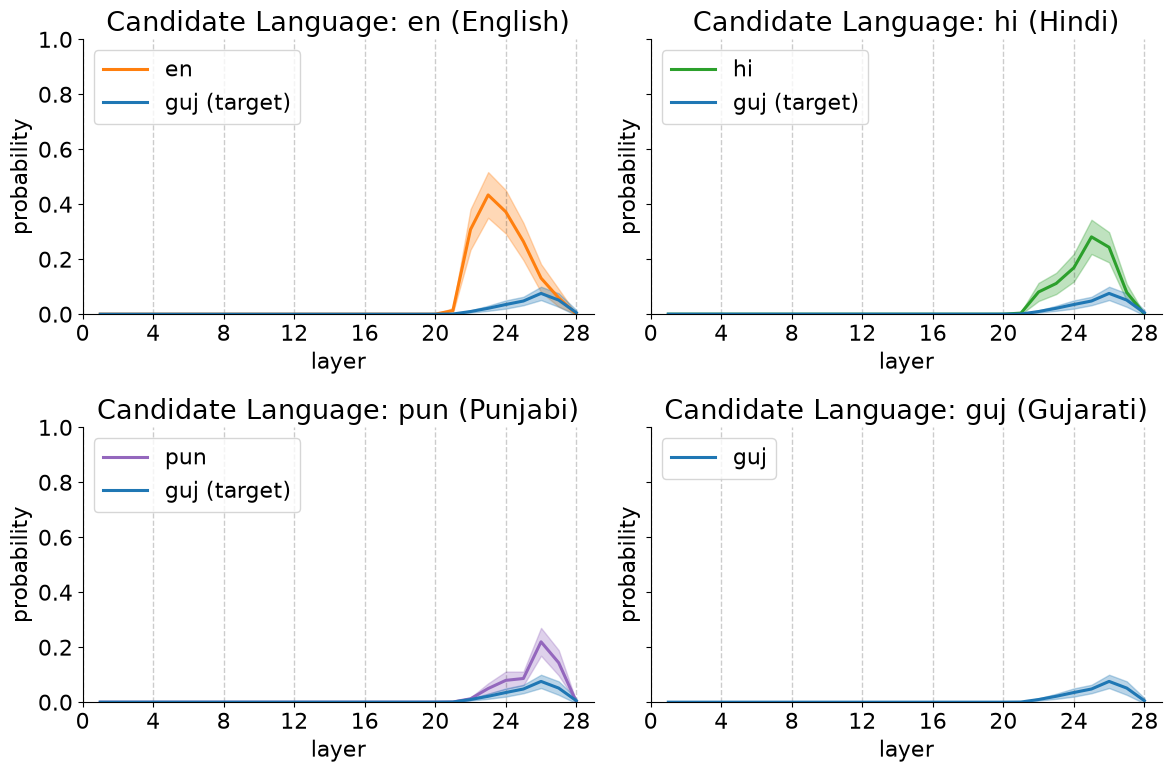

/user1/anish/btp-2026-anish/utils.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


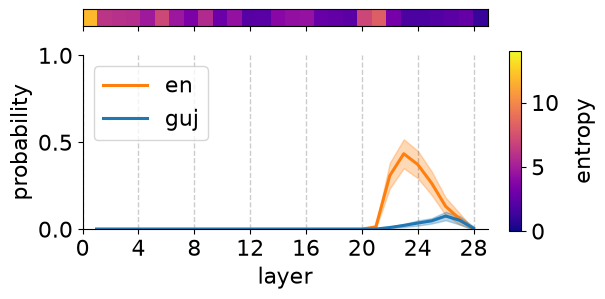

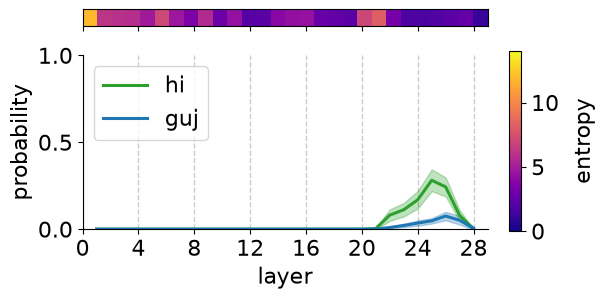

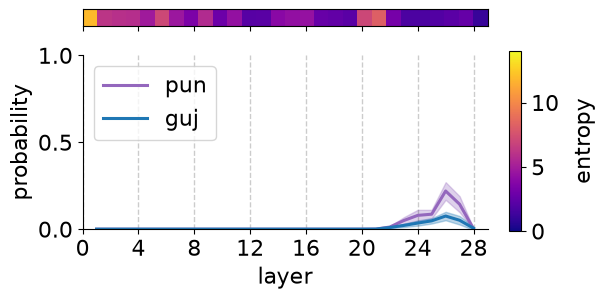

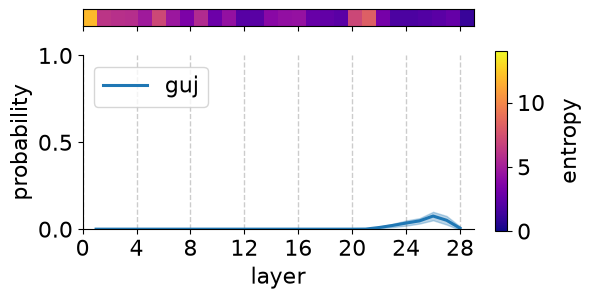

In [15]:
size2tik = {'2b': 4, '7b': 5, '13b': 5, '70b': 10}
tik_step = size2tik.get(model_size, 4)
num_layers = entropy.shape[1]

color_map = {
    'en': 'tab:orange',
    'hi': 'tab:green',
    input_lang: 'tab:purple',
    target_lang: 'tab:blue'
}

# 1. Combined 2x2 Figure with 4 Subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
axes = axes.flatten()

for i, c in enumerate(principal_lang_candidates):
    ax = axes[i]
    c_color = color_map.get(c, 'tab:red')
    
    # Plot candidate language distribution
    plot_ci(ax, lang_probs[c], c, color=c_color, do_lines=True, tik_step=tik_step)
    
    # Overlay target language in blue if the subplot is not already target_lang
    if c != target_lang:
        plot_ci(ax, lang_probs[target_lang], f'{target_lang} (target)', color='tab:blue', do_lines=False, tik_step=tik_step)
        
    ax.set_title(f'Candidate Language: {c} ({lang2english_name.get(c, c)})')    
    ax.set_xlabel('layer')
    ax.set_ylabel('probability')
    ax.set_xlim(0, num_layers + 1)
    ax.set_ylim(0, 1)
    ax.legend(loc='upper left')

plt.tight_layout()
plt.savefig(f'{save_path}/{model_size}_{input_lang}_{target_lang}_4_candidates_grid.pdf', dpi=300, bbox_inches='tight')
plt.show()

# 2. Individual Paper-Style Plots (with Entropy Heatmap) per Candidate Language
for c in candidates:
    c_color = color_map.get(c, 'tab:orange')
    fig, ax, ax2 = plot_ci_plus_heatmap(
        lang_probs[c], 
        entropy, 
        c, 
        color=c_color, 
        tik_step=tik_step, 
        do_colorbar=True,
        nums=[.99, 0.18, 0.025, 0.6]
    )
    if c != target_lang:
        plot_ci(ax2, lang_probs[target_lang], target_lang, color='tab:blue', do_lines=False)
        
    ax2.set_xlabel('layer')
    ax2.set_ylabel('probability')
    ax2.set_xlim(0, num_layers + 1)
    ax2.set_ylim(0, 1)
    ax2.legend(loc='upper left')
    plt.savefig(f'{save_path}/{model_size}_{input_lang}_{target_lang}_probas_ent_candidate_{c}.pdf', dpi=300, bbox_inches='tight')
    plt.show()

#### Block 11: Energy Plot & Saving Latents

Plots the layer-wise energy curve and saves the extracted latent tensors.

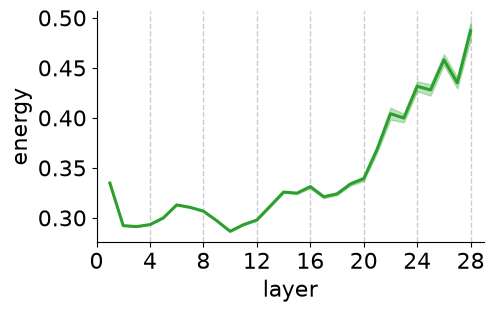

In [16]:
fig, ax2 = plt.subplots(figsize=(5, 3))
plot_ci(ax2, energy, 'energy', color='tab:green', do_lines=True, tik_step=tik_step)
ax2.set_xlabel('layer')
ax2.set_ylabel('energy')
ax2.set_xlim(0, num_layers + 1)

plt.savefig(f'{save_path}/{model_size}_{input_lang}_{target_lang}_energy.pdf', dpi=300, bbox_inches='tight')
plt.show()

torch.save(latents, f'{save_path}/{model_size}_{input_lang}_{target_lang}_latents.pt')
torch.save(lang_probs, f'{save_path}/{model_size}_{input_lang}_{target_lang}_lang_probs.pt')

In [17]:
# ==============================================================================
# Cell: Translation Accuracy & Top-1 Decoded Output Inspection
# ==============================================================================

import pandas as pd
import torch

results = []
correct_exact_count = 0
correct_in_candidate_count = 0

print("Evaluating final-layer predictions across the dataset...\n")

with torch.no_grad():
    for idx, d in enumerate(dataset):
        prompt = d["prompt"]
        expected_target_str = d["out_token_str"].strip()
        expected_token_ids = set(d["out_token_id"])

        # 1. Get logits for the final prompt position
        # Using llama.get_logits (patched in Block 9 to avoid GPU device mismatches)
        logits = llama.get_logits(prompt)
        last_token_logits = logits[0, -1, :]  # Shape: [vocab_size]

        # 2. Top-1 greedy token predicted by the model
        top1_token_id = torch.argmax(last_token_logits).item()
        top1_token_str = (
            tokenizer.decode([top1_token_id])
            .strip()
            .replace("▁", "")
            .replace(" ", "")
        )

        # 3. Top-5 predictions for context
        top5_ids = torch.topk(last_token_logits, k=5).indices.tolist()
        top5_tokens = [
            tokenizer.decode([tid])
            .strip()
            .replace("▁", "")
            .replace(" ", "")
            for tid in top5_ids
        ]

        # 4. Accuracy checks
        # Check A: Did the model output one of the accepted token prefixes/ids?
        is_token_id_match = top1_token_id in expected_token_ids

        # Check B: Does the decoded string match or start the target word?
        is_exact_str_match = (top1_token_str == expected_target_str) or (
            expected_target_str.startswith(top1_token_str)
            and len(top1_token_str) > 0
        )

        is_correct = is_token_id_match or is_exact_str_match
        if is_correct:
            correct_exact_count += 1

        # Check C: Did it output the target word's English or Hindi equivalent instead?
        en_str = str(d.get("en_token_str", ""))
        hi_str = str(d.get("hi_token_str", ""))
        in_lang_str = str(d.get("in_token_str", ""))

        predicted_as = "Other"
        if is_correct:
            predicted_as = f"Target ({target_lang})"
        elif (
            top1_token_str.lower() == en_str.lower()
            or en_str.lower() in top1_token_str.lower()
        ):
            predicted_as = "English (en)"
        elif top1_token_str == hi_str or hi_str in top1_token_str:
            predicted_as = "Hindi (hi)"
        elif top1_token_str == in_lang_str or in_lang_str in top1_token_str:
            predicted_as = f"Input Lang ({input_lang})"

        # Probability assigned to the correct target tokens at layer 28
        target_prob_final = (
            lang_probs[target_lang][idx, -1].item()
            if target_lang in lang_probs
            else 0.0
        )

        results.append(
            {
                "Index": idx,
                "Input Word": in_lang_str,
                "Expected (Target)": expected_target_str,
                "Model Top-1 Output": top1_token_str,
                "Is Correct": "✅ Yes" if is_correct else "❌ No",
                "Predicted Language": predicted_as,
                "Target Prob (L28)": f"{target_prob_final:.4f}",
                "Top-5 Tokens": ", ".join(top5_tokens[:3]),
            }
        )

# Convert to DataFrame for display
eval_df = pd.DataFrame(results)

accuracy = (correct_exact_count / len(dataset)) * 100
print("=" * 60)
print(f"TRANSLATION TASK EVALUATION ({input_lang} -> {target_lang})")
print(f"Total Evaluated Samples : {len(dataset)}")
print(f"Correct Top-1 Predictions: {correct_exact_count} / {len(dataset)}")
print(f"Top-1 Greedy Accuracy   : {accuracy:.2f}%")
print("=" * 60)
print("\nBreakdown of what the model actually outputs:")
print(eval_df["Predicted Language"].value_counts())
print("\nSample Predictions:")
display(
    eval_df[
        [
            "Input Word",
            "Expected (Target)",
            "Model Top-1 Output",
            "Is Correct",
            "Predicted Language",
            "Target Prob (L28)",
            "Top-5 Tokens",
        ]
    ].head(15)
)

Evaluating final-layer predictions across the dataset...

TRANSLATION TASK EVALUATION (pun -> guj)
Total Evaluated Samples : 73
Correct Top-1 Predictions: 14 / 73
Top-1 Greedy Accuracy   : 19.18%

Breakdown of what the model actually outputs:
Predicted Language
Other               53
Target (guj)        14
Input Lang (pun)     6
Name: count, dtype: int64

Sample Predictions:


,Input Word,Expected (Target),Model Top-1 Output,Is Correct,Predicted Language,Target Prob (L28),Top-5 Tokens
0,ਕਿਤਾਬ,પુસ્તક,ਕਿ,❌ No,Other,0.0001,"ਕਿ, ਬ, ਪ"
1,ਮਿੱਟੀ,માટી,ਮ,❌ No,Other,0.0000,"ਮ, ਧ, ਪ"
2,ਪਹਾੜ,પર્વત,પ,✅ Yes,Target (guj),0.0000,"પ, મા, प"
3,ਦਿਲ,હૃદય,ਦ,❌ No,Other,0.0000,"ਦ, ਹ, ਮਨ"
4,ਹੱਥ,હાથ,ਹ,❌ No,Other,0.0001,"ਹ, હા, हात"
5,ਦਿਨ,દિવસ,ਦ,❌ No,Other,0.0000,"ਦ, ଦିନ, ਰੋ"
6,ਪਿੰਡ,ગામ,ਪ,❌ No,Other,0.0001,"ਪ, ਛ, ਨ"
7,ਫਲ,ફળ,ફળ,✅ Yes,Target (guj),0.3653,"ફળ, ਫਲ, ਫ਼ਲ"
8,ਗੀਤ,ગીત,ગ,✅ Yes,Target (guj),0.0047,"ગ, ગા, ਗੀਤ"
9,ਪਾਣੀ,પાણી,ਪਾ,❌ No,Other,0.0000,"ਪਾ, પા, पानी"


In [18]:
# Inspect what the model is actually predicting instead of Tamil
print("Most common tokens predicted instead of the target language:")
print(eval_df['Model Top-1 Output'].value_counts().head(15))

print("\nSample predictions marked as 'Other':")
display(eval_df[eval_df['Predicted Language'] == 'Other'][['Input Word', 'Expected (Target)', 'Model Top-1 Output', 'Top-5 Tokens']].head(10))

Most common tokens predicted instead of the target language:
Model Top-1 Output
ਦ     4
ਪ     4
ਅ     4
ਸ     3
ਹ     2
ਸਮ    2
ਦੋ    2
ਨ     2
ਸਥ    2
ભા    2
ਕਿ    1
ਮ     1
પ     1
ફળ    1
ગ     1
Name: count, dtype: int64

Sample predictions marked as 'Other':


,Input Word,Expected (Target),Model Top-1 Output,Top-5 Tokens
0,ਕਿਤਾਬ,પુસ્તક,ਕਿ,"ਕਿ, ਬ, ਪ"
1,ਮਿੱਟੀ,માટી,ਮ,"ਮ, ਧ, ਪ"
3,ਦਿਲ,હૃદય,ਦ,"ਦ, ਹ, ਮਨ"
4,ਹੱਥ,હાથ,ਹ,"ਹ, હા, हात"
5,ਦਿਨ,દિવસ,ਦ,"ਦ, ଦିନ, ਰੋ"
6,ਪਿੰਡ,ગામ,ਪ,"ਪ, ਛ, ਨ"
9,ਪਾਣੀ,પાણી,ਪਾ,"ਪਾ, પા, पानी"
10,ਕਾਨੂੰਨ,કાયદો,ਕਾਨੂੰ,"ਕਾਨੂੰ, ਲਾ, ਅ"
11,ਸਮੁੰਦਰ,સમુદ્ર,ਸਮ,"ਸਮ, ਸ, ਸਾ"
12,ਅੱਗ,આગ,ਅ,"ਅ, ਜ, ਆ"
